
# Gender Detection Using Machine Learning

## Project Information
- **Project Name:** Gender Detection
- **Project Code:** PRAICP-1001-GenderDetc
- **Domain:** Data Science / Machine Learning
- **Project Type:** Image Classification

## Business Objective
To develop a machine learning model that classifies images into the Male and Female categories using image preprocessing and machine learning techniques.

## Project Goals
1. Load and understand the image dataset.
2. Perform image preprocessing.
3. Explore and visualize the dataset.
4. Train suitable classification models.
5. Compare model performance.
6. Evaluate the selected model.
7. Test predictions using new images.
8. Save the final trained model.


In [1]:
# Step 1: Environment Setup

import os
import sys
import platform
import importlib.util

print("Python Version:", sys.version)
print("Operating System:", platform.system())
print("Platform:", platform.platform())

# Check required libraries
libraries = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "PIL",
    "cv2",
    "sklearn",
    "tensorflow",
    "torch"
]

print("\nLibrary Availability:\n")

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if available else 'Not Installed'}")

Python Version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Operating System: Windows
Platform: Windows-11-10.0.26300-SP0

Library Availability:

numpy: Installed
pandas: Installed
matplotlib: Installed
seaborn: Installed
PIL: Installed
cv2: Installed
sklearn: Installed
tensorflow: Installed
torch: Not Installed


In [2]:
import os
from pathlib import Path
import pandas as pd
from PIL import Image
from collections import Counter

In [3]:
# Dataset location
dataset_path = Path(
    r"C:\Users\prana\Downloads\PRAICP-1001-GenderDetc"
)

# Check whether the dataset folder exists
if dataset_path.exists():
    print("Dataset folder found successfully!")
else:
    print("Dataset folder not found. Please check the path.")

# Display folder structure
print("\nDataset Folder Structure:\n")

for root, dirs, files in os.walk(dataset_path):
    level = len(Path(root).relative_to(dataset_path).parts)

    indent = "    " * level

    print(f"{indent}{Path(root).name}/")

    if level >= 3:
        dirs[:] = []

Dataset folder found successfully!

Dataset Folder Structure:

PRAICP-1001-GenderDetc/
    Data/
        gender_dataset_face/
            man/
            woman/


In [5]:
# Supported image formats
image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Find all image files
image_files = [
    file for file in dataset_path.rglob("*")
    if file.is_file()
    and file.suffix.lower() in image_extensions
]

print("Total Images Found:", len(image_files))

# Display image counts by parent folder
folder_counts = Counter(
    file.parent.name for file in image_files
)

print("\nImages by Folder:\n")

for folder, count in folder_counts.items():
    print(f"{folder}: {count}")

Total Images Found: 2307

Images by Folder:

man: 1173
woman: 1134


In [6]:
# Step 3: Image Data Validation

image_records = []
corrupted_images = []

for image_path in image_files:

    try:
        with Image.open(image_path) as img:

            # Verify image can be loaded
            img.load()

            image_records.append({
                "filename": image_path.name,
                "filepath": str(image_path),
                "class": image_path.parent.name,
                "format": img.format,
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "file_size_kb": round(
                    image_path.stat().st_size / 1024, 2
                )
            })

    except Exception as e:
        corrupted_images.append({
            "filepath": str(image_path),
            "error": str(e)
        })

In [7]:
# Create DataFrames
image_df = pd.DataFrame(image_records)
corrupted_df = pd.DataFrame(corrupted_images)

print("Valid Images:", len(image_df))
print("Corrupted Images:", len(corrupted_df))

print("\nImage Information:")
display(image_df.head())

Valid Images: 2307
Corrupted Images: 0

Image Information:


,filename,filepath,class,format,width,height,mode,file_size_kb
0,face_0.jpg,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,man,JPEG,121,170,RGB,11.11
1,face_1.jpg,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,man,JPEG,106,146,RGB,9.31
2,face_10.jpg,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,man,JPEG,371,476,RGB,52.02
3,face_1000.jpg,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,man,JPEG,118,198,RGB,6.53
4,face_1001.jpg,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,man,JPEG,165,191,RGB,11.06


In [8]:
# Analyze image formats
print("Image Format Distribution:")
display(image_df["format"].value_counts())

# Analyze image dimensions
print("\nImage Dimension Distribution:")
display(
    image_df.groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(15)
)

Image Format Distribution:


format
JPEG    2307
Name: count, dtype: int64


Image Dimension Distribution:


,width,height,image_count
450,106,146,4
130,67,86,4
513,113,147,4
698,130,173,3
810,141,194,3
179,74,98,3
973,157,204,3
67,55,76,3
403,101,134,3
976,157,209,3


In [9]:
# Analyze image modes
print("\nImage Mode Distribution:")
display(image_df["mode"].value_counts())

# Statistical summary
print("\nImage Dimensions Summary:")
display(
    image_df[["width", "height", "file_size_kb"]].describe()
)


Image Mode Distribution:


mode
RGB    2307
Name: count, dtype: int64


Image Dimensions Summary:


,width,height,file_size_kb
count,2307.000000,2307.000000,2307.000000
mean,203.317729,270.235804,30.539926
std,168.555876,222.478606,93.357480
min,24.000000,25.000000,1.150000
25%,112.000000,149.000000,7.695000
50%,160.000000,214.000000,13.610000
75%,240.500000,320.000000,26.545000
max,2269.000000,3068.000000,2434.300000


In [10]:
## Check exact duplicate images

In [12]:
import hashlib

def calculate_image_hash(filepath):
    hash_object = hashlib.md5()

    with open(filepath, "rb") as file:
        for chunk in iter(lambda: file.read(4096), b""):
            hash_object.update(chunk)

    return hash_object.hexdigest()


image_df["image_hash"] = image_df["filepath"].apply(
    calculate_image_hash
)

duplicate_images = image_df[
    image_df.duplicated(
        subset=["image_hash"],
        keep=False
    )
].sort_values("image_hash")

print("Total Exact Duplicate Image Records:",
      len(duplicate_images))

if len(duplicate_images) > 0:
    display(
        duplicate_images[
            ["filename", "class", "filepath", "image_hash"]
        ].head(20)
    )
else:
    print("No exact duplicate images found.")

Total Exact Duplicate Image Records: 8


,filename,class,filepath,image_hash
882,face_620.jpg,man,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,1656e6a7a44fbaafb9334f79d37d7b19
2110,face_775.jpg,woman,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,1656e6a7a44fbaafb9334f79d37d7b19
2229,face_925.jpg,woman,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,3a0bbc3d3ed56351eae403ce31669472
2306,face_999.jpg,woman,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,3a0bbc3d3ed56351eae403ce31669472
22,face_1024.jpg,man,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,a2cb4495656c2659ead98dc72bfafb26
301,face_1335.jpg,man,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,a2cb4495656c2659ead98dc72bfafb26
53,face_1061.jpg,man,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,f553f11603da6d88ff4bced385cfc4fd
802,face_524.jpg,man,C:\Users\prana\Downloads\PRAICP-1001-GenderDet...,f553f11603da6d88ff4bced385cfc4fd


Number of Duplicate Groups: 4

Duplicate Group 1
          filename  class                                           filepath
882   face_620.jpg    man  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...
2110  face_775.jpg  woman  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...

Duplicate Group 2
          filename  class                                           filepath
2229  face_925.jpg  woman  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...
2306  face_999.jpg  woman  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...

Duplicate Group 3
          filename class                                           filepath
22   face_1024.jpg   man  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...
301  face_1335.jpg   man  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...

Duplicate Group 4
          filename class                                           filepath
53   face_1061.jpg   man  C:\Users\prana\Downloads\PRAICP-1001-GenderDet...
802   face_524.jpg   man  C:\Users\prana\Downloads\P

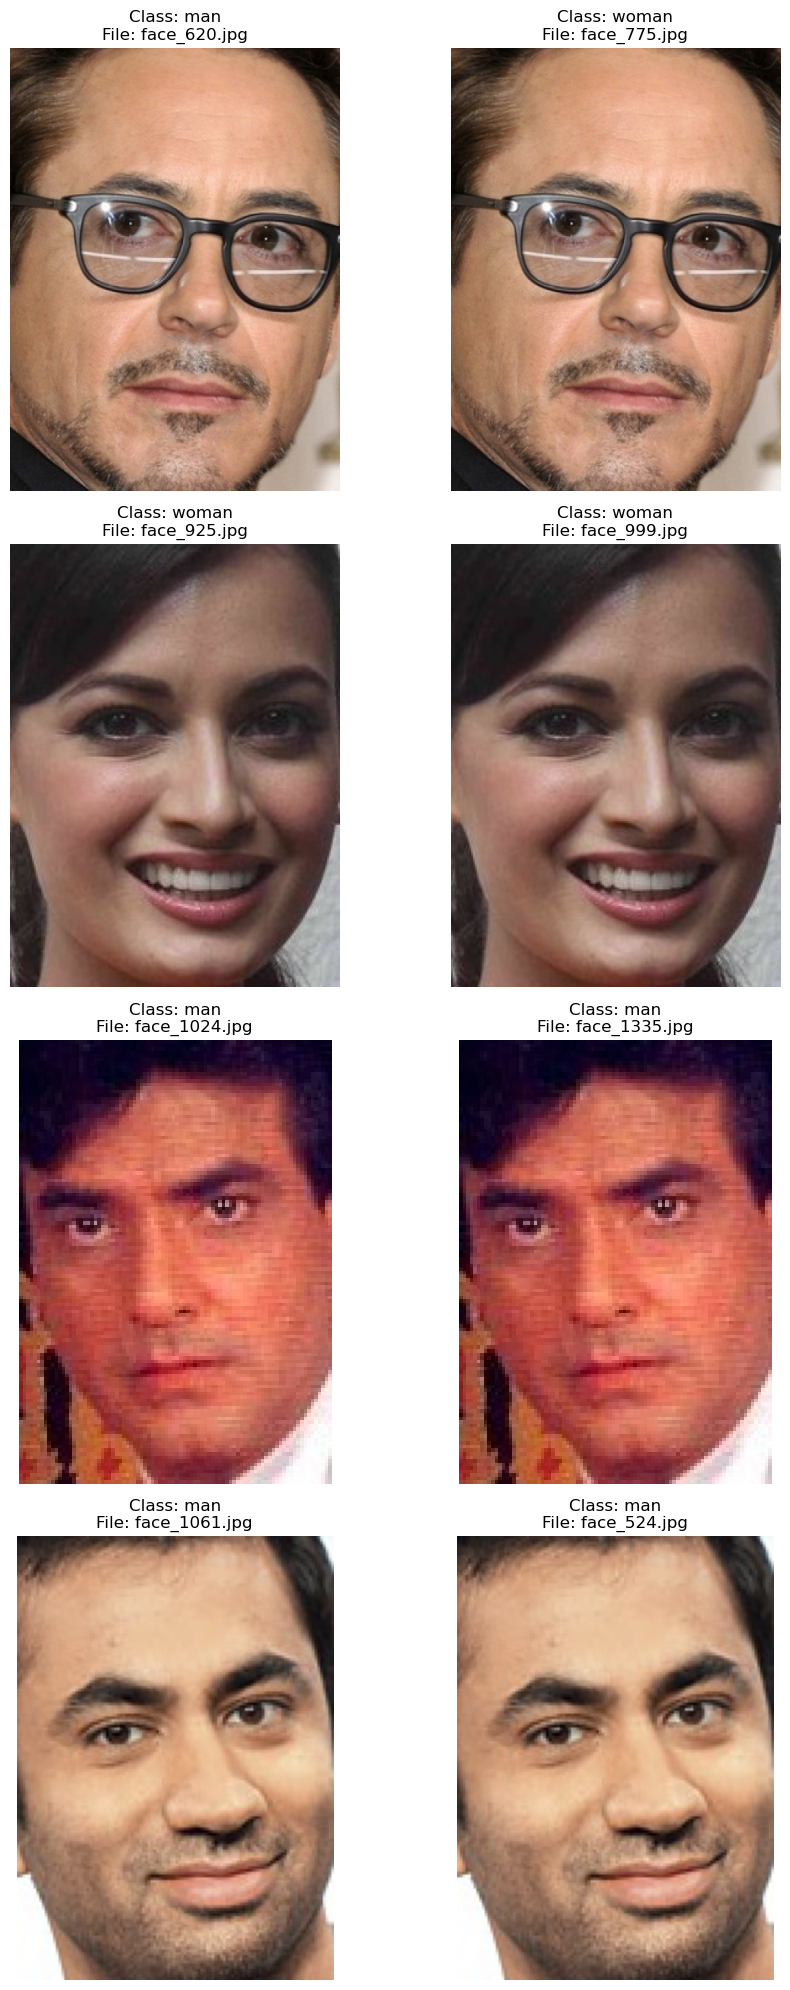

In [16]:
# Display duplicate image pairs
import matplotlib.pyplot as plt
from PIL import Image

# Group duplicate images by their hash
duplicate_groups = list(
    duplicate_images.groupby("image_hash")
)

print("Number of Duplicate Groups:", len(duplicate_groups))

# Create visualization
fig, axes = plt.subplots(
    len(duplicate_groups),
    2,
    figsize=(10, 5 * len(duplicate_groups))
)

if len(duplicate_groups) == 1:
    axes = axes.reshape(1, 2)

# Display duplicate pairs
for i, (image_hash, group) in enumerate(duplicate_groups):

    for j, (_, record) in enumerate(group.iterrows()):

        img = Image.open(record["filepath"])

        axes[i, j].imshow(img)

        axes[i, j].set_title(
            f"Class: {record['class']}\n"
            f"File: {record['filename']}"
        )

        axes[i, j].axis("off")

    print(f"\nDuplicate Group {i + 1}")
    print(group[["filename", "class", "filepath"]])

plt.tight_layout()
plt.show()

In [17]:
# Remove exact duplicates safely


# Create a copy of the image dataset
cleaned_image_df = image_df.copy()

# Identify conflicting duplicate groups
conflicting_hashes = (
    duplicate_images.groupby("image_hash")["class"]
    .nunique()
)

conflicting_hashes = conflicting_hashes[
    conflicting_hashes > 1
].index

print("Conflicting Duplicate Groups:",
      len(conflicting_hashes))

# Remove all duplicate records, keeping one per hash
# For conflicting labels, exclude the entire group
cleaned_image_df = cleaned_image_df[
    ~cleaned_image_df["image_hash"].isin(conflicting_hashes)
]

cleaned_image_df = cleaned_image_df.drop_duplicates(
    subset="image_hash",
    keep="first"
).reset_index(drop=True)

print("\nOriginal Image Count:", len(image_df))
print("Cleaned Image Count:", len(cleaned_image_df))
print("Removed Image Records:",
      len(image_df) - len(cleaned_image_df))

print("\nCleaned Class Distribution:")
display(cleaned_image_df["class"].value_counts())

Conflicting Duplicate Groups: 1

Original Image Count: 2307
Cleaned Image Count: 2302
Removed Image Records: 5

Cleaned Class Distribution:


class
man      1170
woman    1132
Name: count, dtype: int64

# Exploratory Data Analysis (EDA)

In [18]:
# Step 4: Exploratory Data Analysis

import matplotlib.pyplot as plt
import seaborn as sns

# Class distribution
class_counts = cleaned_image_df["class"].value_counts()

print("Class Distribution:")
display(class_counts)

# Calculate percentages
class_percentages = (
    class_counts / class_counts.sum()
) * 100

print("\nClass Percentages:")
display(class_percentages.round(2))

Class Distribution:


class
man      1170
woman    1132
Name: count, dtype: int64


Class Percentages:


class
man      50.83
woman    49.17
Name: count, dtype: float64

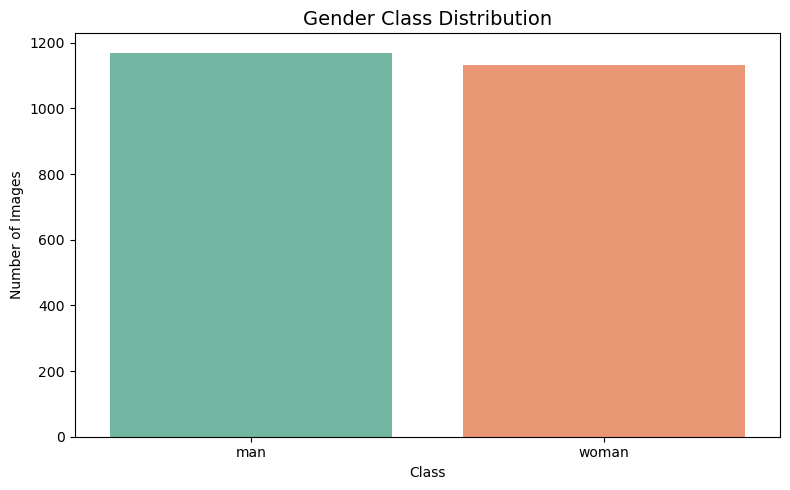

In [19]:
# Visualize class distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cleaned_image_df,
    x="class",
    hue="class",
    palette="Set2",
    legend=False
)

plt.title("Gender Class Distribution", fontsize=14)
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

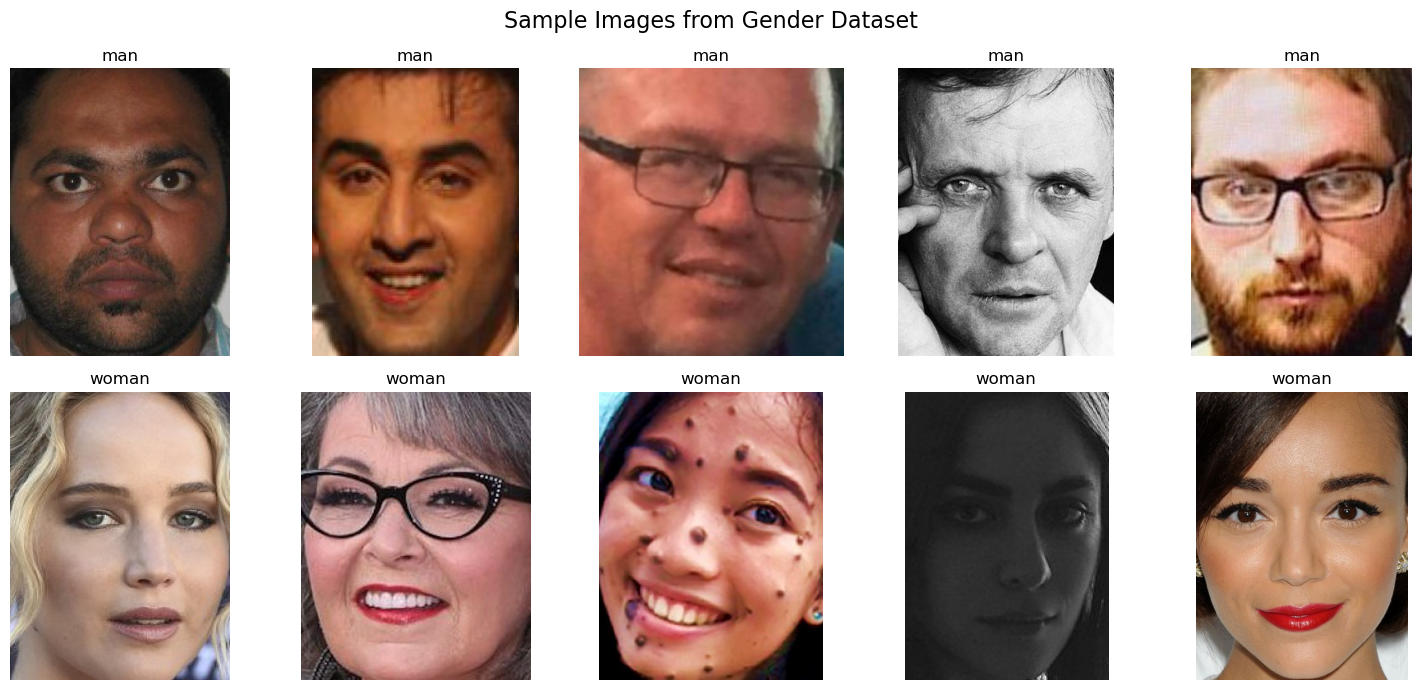

In [20]:
# Display sample images from both classes

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

classes = ["man", "woman"]

for row, class_name in enumerate(classes):

    sample_images = cleaned_image_df[
        cleaned_image_df["class"] == class_name
    ].sample(n=5, random_state=42)

    for col, (_, record) in enumerate(sample_images.iterrows()):

        img = Image.open(record["filepath"]).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle(
    "Sample Images from Gender Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

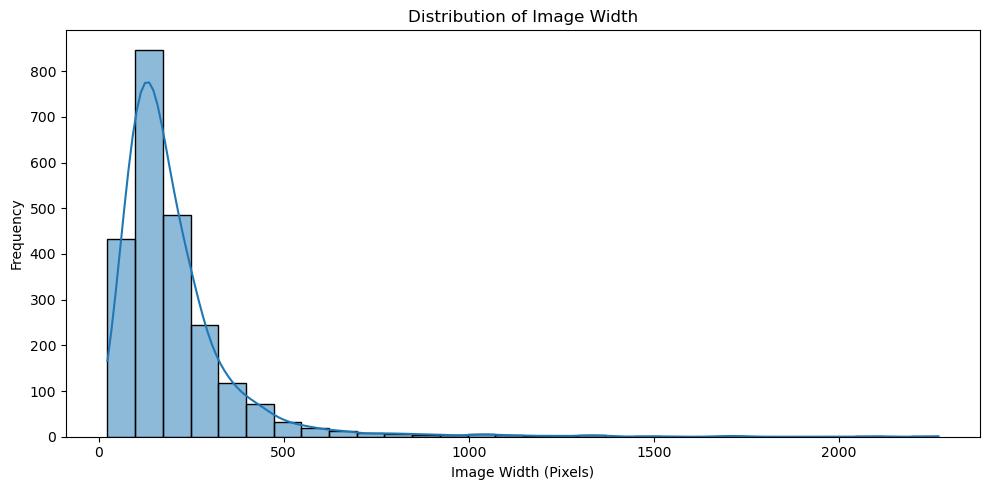

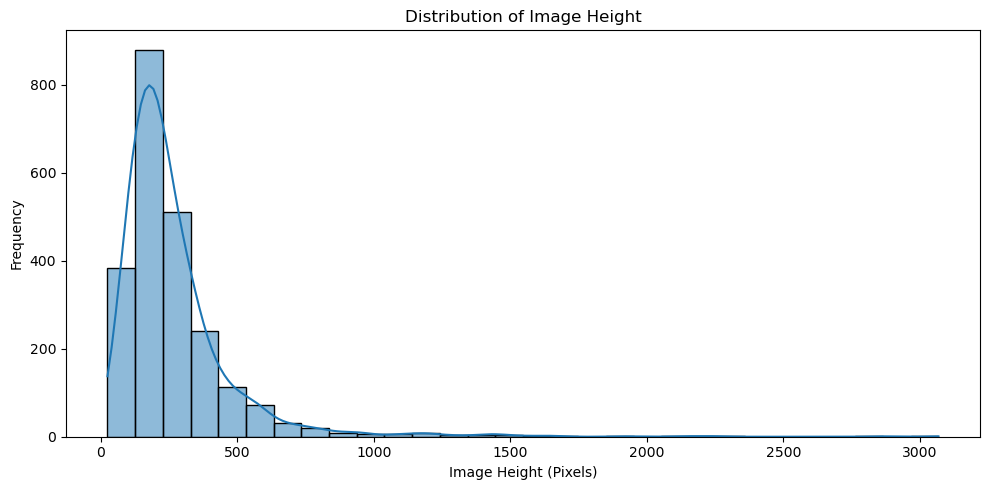

In [21]:
# Analyze image dimensions

plt.figure(figsize=(10, 5))

sns.histplot(
    data=cleaned_image_df,
    x="width",
    bins=30,
    kde=True
)

plt.title("Distribution of Image Width")
plt.xlabel("Image Width (Pixels)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=cleaned_image_df,
    x="height",
    bins=30,
    kde=True
)

plt.title("Distribution of Image Height")
plt.xlabel("Image Height (Pixels)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Analyze image aspect ratios

Aspect Ratio Statistics:


count    2302.000000
mean        0.753384
std         0.067972
min         0.429530
25%         0.711538
50%         0.747706
75%         0.786348
max         1.455556
Name: aspect_ratio, dtype: float64

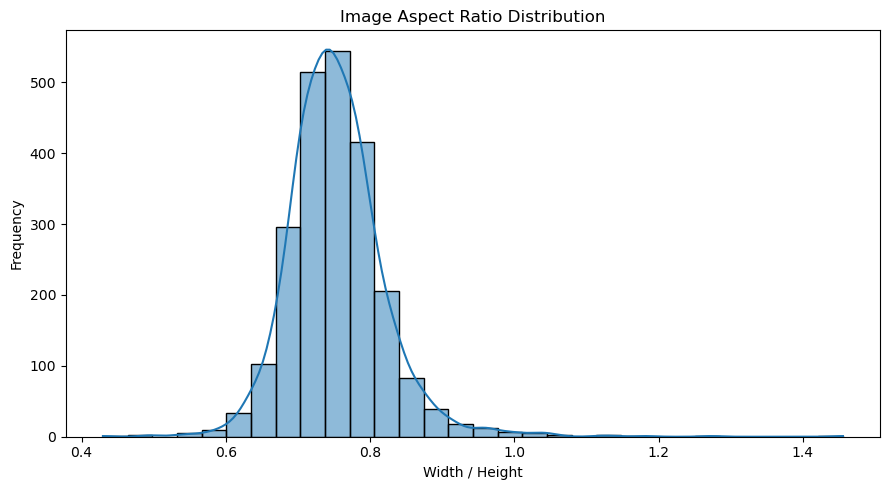

In [24]:
# Calculate aspect ratio
cleaned_image_df["aspect_ratio"] = (
    cleaned_image_df["width"] /
    cleaned_image_df["height"]
)

print("Aspect Ratio Statistics:")
display(cleaned_image_df["aspect_ratio"].describe())

# Visualize aspect ratio distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=cleaned_image_df,
    x="aspect_ratio",
    bins=30,
    kde=True
)

plt.title("Image Aspect Ratio Distribution")
plt.xlabel("Width / Height")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

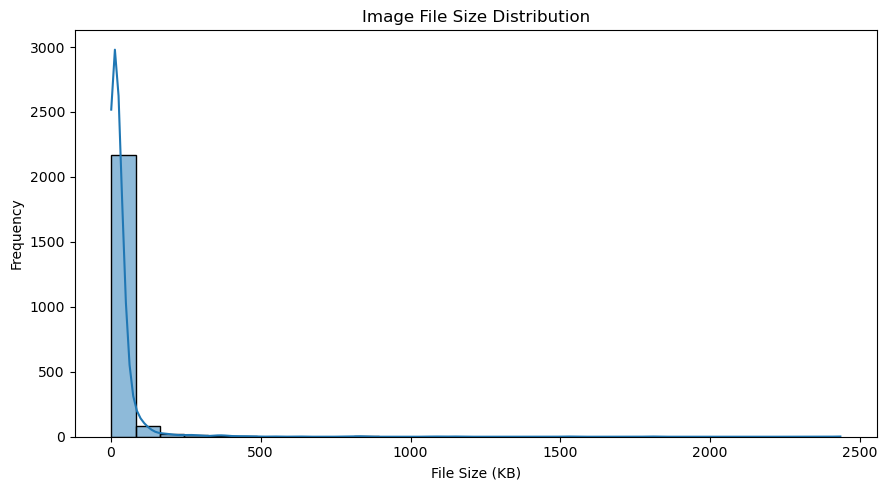

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=cleaned_image_df,
    x="file_size_kb",
    bins=30,
    kde=True
)

plt.title("Image File Size Distribution")
plt.xlabel("File Size (KB)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [26]:
print("File Size Statistics (KB):")
display(cleaned_image_df["file_size_kb"].describe())

File Size Statistics (KB):


count    2302.000000
mean       30.521421
std        93.443508
min         1.150000
25%         7.692500
50%        13.595000
75%        26.507500
max      2434.300000
Name: file_size_kb, dtype: float64

In [27]:
# Step 5: Dataset Preparation

from sklearn.model_selection import train_test_split

# Create numerical labels
label_mapping = {
    "man": 0,
    "woman": 1
}

cleaned_image_df["label"] = (
    cleaned_image_df["class"].map(label_mapping)
)

# Check labels
print("Label Mapping:", label_mapping)

print("\nLabel Distribution:")
display(cleaned_image_df["label"].value_counts())

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    cleaned_image_df,
    test_size=0.30,
    random_state=42,
    stratify=cleaned_image_df["label"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

Label Mapping: {'man': 0, 'woman': 1}

Label Distribution:


label
0    1170
1    1132
Name: count, dtype: int64

In [28]:
# Reset indexes
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset Split Results:")
print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print(
    "\nTotal Images:",
    len(train_df) + len(val_df) + len(test_df)
)


Dataset Split Results:
Training Images: 1611
Validation Images: 345
Testing Images: 346

Total Images: 2302


In [33]:
# Check class distribution in each dataset split

for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:

    print(f"\n{name} Dataset")
    print("-" * 35)

    print(data["class"].value_counts())

    print("\nPercentage Distribution:")
    print(
        (data["class"].value_counts(normalize=True) * 100)
        .round(2)
    )


Training Dataset
-----------------------------------
class
man      819
woman    792
Name: count, dtype: int64

Percentage Distribution:
class
man      50.84
woman    49.16
Name: proportion, dtype: float64

Validation Dataset
-----------------------------------
class
man      175
woman    170
Name: count, dtype: int64

Percentage Distribution:
class
man      50.72
woman    49.28
Name: proportion, dtype: float64

Testing Dataset
-----------------------------------
class
man      176
woman    170
Name: count, dtype: int64

Percentage Distribution:
class
man      50.87
woman    49.13
Name: proportion, dtype: float64


In [34]:
# Step 6: Image Preprocessing

import numpy as np
from PIL import Image

# Define image configuration
IMG_SIZE = 160
IMAGE_CHANNELS = 3

def preprocess_image(image_path, img_size=IMG_SIZE):

    # Open image and convert to RGB
    image = Image.open(image_path).convert("RGB")

    original_width, original_height = image.size

    # Calculate aspect-ratio-preserving dimensions
    scale = min(
        img_size / original_width,
        img_size / original_height
    )

    new_width = max(1, round(original_width * scale))
    new_height = max(1, round(original_height * scale))

    # Resize image
    image = image.resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS
    )

    # Create black square background
    canvas = Image.new(
        "RGB",
        (img_size, img_size),
        (0, 0, 0)
    )

    # Calculate padding position
    left = (img_size - new_width) // 2
    top = (img_size - new_height) // 2

    # Paste resized image onto canvas
    canvas.paste(image, (left, top))

    # Convert to NumPy array
    image_array = np.asarray(
        canvas,
        dtype=np.float32
    )

    # Normalize pixel values to 0-1
    image_array = image_array / 255.0

    return image_array

In [36]:
# Select one sample image from training dataset

sample_path = train_df.iloc[0]["filepath"]

# Process image
processed_image = preprocess_image(sample_path)

# Display image information
print("Original Image Path:", sample_path)

print("\nProcessed Image Shape:",
      processed_image.shape)

print("Data Type:",
      processed_image.dtype)

print("Minimum Pixel Value:",
      processed_image.min())

print("Maximum Pixel Value:",
      processed_image.max())

Original Image Path: C:\Users\prana\Downloads\PRAICP-1001-GenderDetc\Data\gender_dataset_face\woman\face_1177.jpg

Processed Image Shape: (160, 160, 3)
Data Type: float32
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


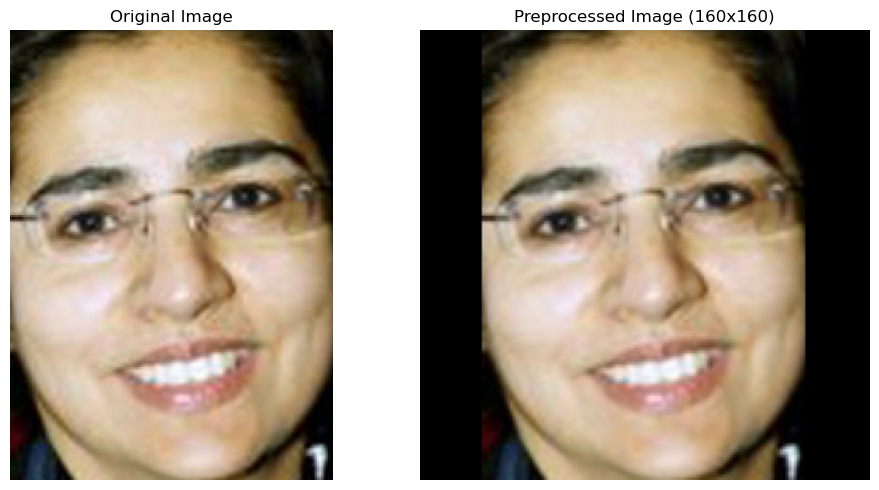

In [38]:
# Load original image
original_image = Image.open(sample_path).convert("RGB")

# Display original and processed images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title("Preprocessed Image (160x160)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Build the image-loading pipeline

In [40]:
# Step 7: Image Data Pipeline

BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Image Channels:", IMAGE_CHANNELS)
print("TensorFlow:", tf.__version__)

Image Size: 160
Batch Size: 16
Image Channels: 3
TensorFlow: 2.21.0


In [41]:
# Create TensorFlow preprocessing function
def load_and_preprocess_image(filepath, label):

    # Read image file
    image = tf.io.read_file(filepath)

    # Decode JPEG image
    image = tf.io.decode_jpeg(image, channels=3)

    # Convert image to float32
    image = tf.cast(image, tf.float32)

    # Resize while preserving aspect ratio
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE
    )

    # Normalize pixels between 0 and 1
    image = image / 255.0

    # Convert label to integer
    label = tf.cast(label, tf.int32)

    return image, label

In [42]:
# Create dataset pipeline
def create_dataset(dataframe, training=False):

    filepaths = dataframe["filepath"].values
    labels = dataframe["label"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_dataset = create_dataset(train_df, training=True)
val_dataset = create_dataset(val_df)
test_dataset = create_dataset(test_df)

print("Datasets created successfully.")

Datasets created successfully.


In [44]:
# Verify dataset batches
for images, labels in train_dataset.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)
    print("Image Data Type:", images.dtype)
    print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
    print("Maximum Pixel Value:", tf.reduce_max(images).numpy())
    print("Sample Labels:", labels.numpy())

Image Batch Shape: (16, 160, 160, 3)
Label Batch Shape: (16,)
Image Data Type: <dtype: 'float32'>
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0
Sample Labels: [1 0 0 0 0 1 0 0 0 1 1 0 1 0 1 1]


In [46]:
# Build the first CNN model

from tensorflow.keras import layers, models, callbacks

print("CNN components imported successfully.")

CNN components imported successfully.


### Build CNN architecture

In [47]:
cnn_model = models.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # First convolution block
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),

    # Binary classification output
    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("CNN model created successfully.")

CNN model created successfully.


In [48]:
# Display model architecture

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 160, 160, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 80, 80, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 80, 80, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 40, 40, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 40, 40, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 20, 20, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 27,809 (108.63 KB)

 Trainable params: 27,809 (108.63 KB)

 Non-trainable params: 0 (0.00 B)

## Train the CNN model

In [49]:
from pathlib import Path

# Create model output directory
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

checkpoint_path = model_dir / "best_gender_cnn.keras"

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = callbacks.ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

print("Training callbacks configured.")
print("Checkpoint path:", checkpoint_path)

Training callbacks configured.
Checkpoint path: models\best_gender_cnn.keras


In [50]:
# Train the CNN model
EPOCHS = 15

history = cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[
        early_stopping,
        model_checkpoint,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/15


C:\Users\prana\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


100/101 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.4988 - loss: 0.6941 - precision: 0.4545 - recall: 0.0759
Epoch 1: val_loss improved from None to 0.69247, saving model to models\best_gender_cnn.keras

Epoch 1: finished saving model to models\best_gender_cnn.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 86ms/step - accuracy: 0.4966 - loss: 0.6942 - precision: 0.4336 - recall: 0.0783 - val_accuracy: 0.4928 - val_loss: 0.6925 - val_precision: 0.4928 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/15
100/101 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.5519 - loss: 0.6878 - precision: 0.5477 - recall: 0.5038
Epoch 2: val_loss improved from 0.69247 to 0.67090, saving model to models\best_gender_cnn.keras

Epoch 2: finished saving model to models\best_gender_cnn.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 9s 89ms/step - accuracy: 0.5525 - loss: 0.6877 - precision: 0.5488 - recall: 0.5038 - val_accuracy: 0.6203 - val_loss: 0.6709 - val_precision: 0.6822 - val_recall: 0.4294 - learning_rate: 0.

In [52]:
# Display training results

history_df = pd.DataFrame(history.history)

print("Training History:")
display(history_df)

print("\nBest Validation Accuracy:",
      round(history_df["val_accuracy"].max(), 4))

print("Best Validation Loss:",
      round(history_df["val_loss"].min(), 4))

print("Completed Epochs:",
      len(history_df))

Training History:


,accuracy,loss,precision,recall,val_accuracy,val_loss,val_precision,val_recall,learning_rate
0,0.496586,0.694169,0.433566,0.078283,0.492754,0.692474,0.492754,1.000000,0.0010
1,0.552452,0.687684,0.548831,0.503788,0.620290,0.670896,0.682243,0.429412,0.0010
2,0.641217,0.651303,0.642287,0.609848,0.617391,0.631878,0.577869,0.829412,0.0010
3,0.689013,0.604880,0.675513,0.707071,0.686957,0.603504,0.686747,0.670588,0.0010
4,0.696462,0.598209,0.691530,0.690657,0.701449,0.588254,0.703030,0.682353,0.0010
5,0.708876,0.581924,0.706258,0.698232,0.686957,0.597615,0.727941,0.582353,0.0010
6,0.725016,0.561664,0.718946,0.723485,0.733333,0.573269,0.743750,0.700000,0.0010
7,0.726878,0.550883,0.737197,0.690657,0.721739,0.572589,0.734177,0.682353,0.0010
8,0.739913,0.543809,0.746367,0.713384,0.710145,0.565265,0.727273,0.658824,0.0010
9,0.726878,0.556058,0.736559,0.691919,0.713043,0.567553,0.712575,0.700000,0.0010



Best Validation Accuracy: 0.7333
Best Validation Loss: 0.5391
Completed Epochs: 15


# Visualize model performance


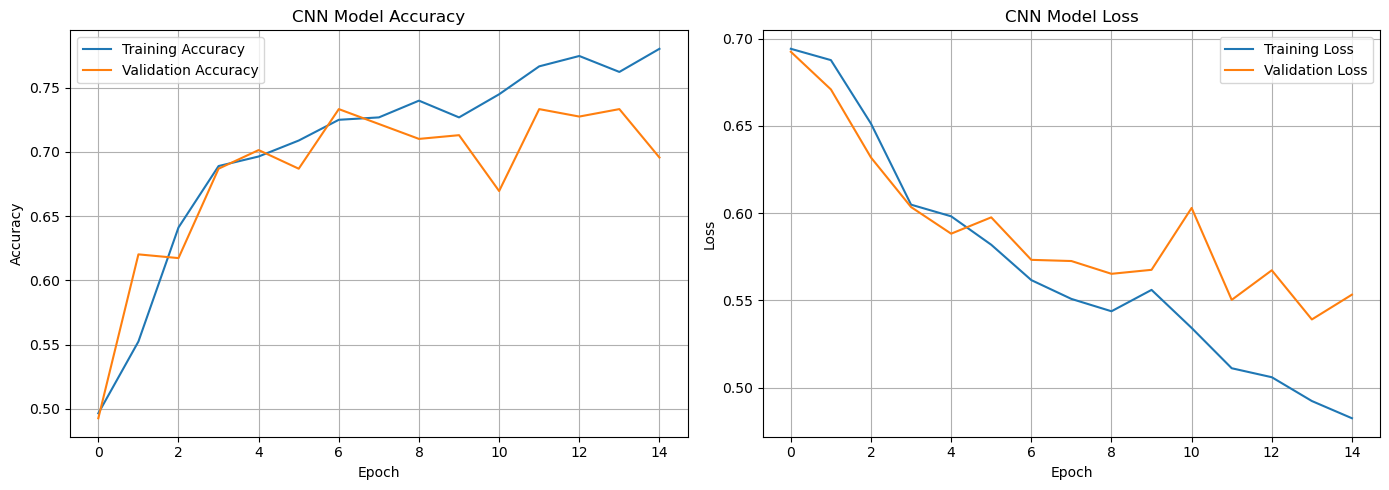

In [53]:
# Step 10: Training Performance Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("CNN Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(
    history.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("CNN Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [55]:
best_epoch = history_df["val_loss"].idxmin()

print("Best Epoch:", best_epoch + 1)

print("Training Accuracy at Best Epoch:",
      round(history_df.loc[best_epoch, "accuracy"], 4))

print("Validation Accuracy at Best Epoch:",
      round(history_df.loc[best_epoch, "val_accuracy"], 4))

print("Training Loss at Best Epoch:",
      round(history_df.loc[best_epoch, "loss"], 4))

print("Validation Loss at Best Epoch:",
      round(history_df.loc[best_epoch, "val_loss"], 4))

Best Epoch: 14
Training Accuracy at Best Epoch: 0.7623
Validation Accuracy at Best Epoch: 0.7333
Training Loss at Best Epoch: 0.4924
Validation Loss at Best Epoch: 0.5391


# Improve the CNN with data augmentation

In [57]:
# Step 11: Data Augmentation

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation configured successfully.")

Data augmentation configured successfully.


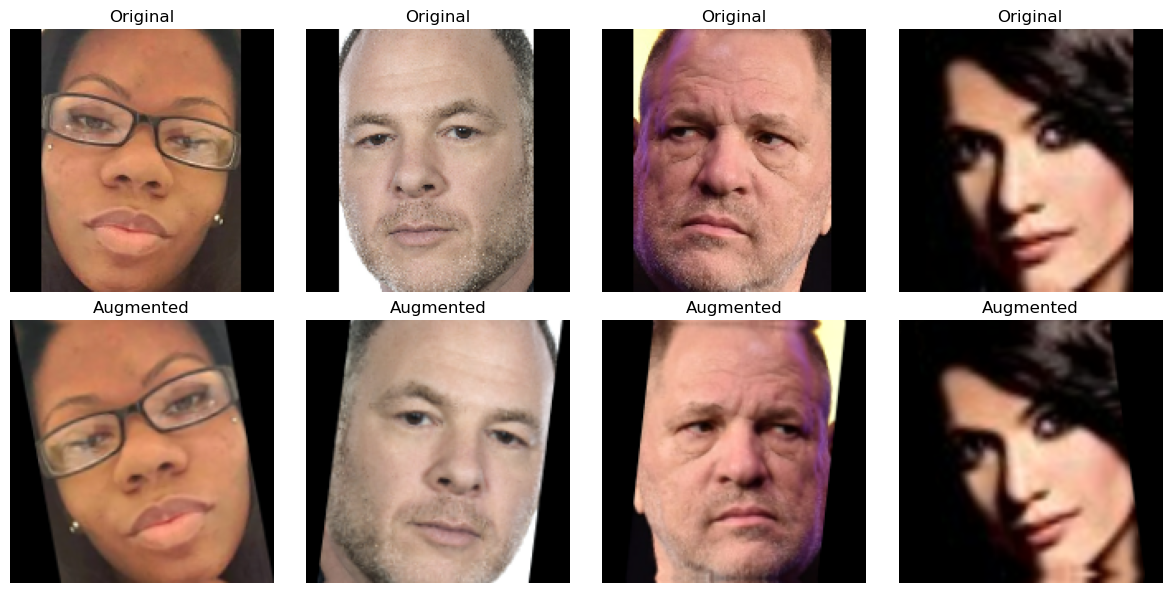

In [58]:
# Select one training batch
for images, labels in train_dataset.take(1):
    sample_batch = images[:4]

# Generate augmented images
augmented_batch = data_augmentation(
    sample_batch,
    training=True
)

# Plot original and augmented images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):

    axes[0, i].imshow(sample_batch[i].numpy())
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        tf.clip_by_value(
            augmented_batch[i],
            0,
            1
        ).numpy()
    )
    axes[1, i].set_title("Augmented")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# Build improved CNN model

In [59]:
improved_cnn = models.Sequential([

    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(16, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

improved_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Improved CNN created successfully.")

Improved CNN created successfully.


In [60]:
# Display improved model summary

improved_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 160, 160, 16)        │             432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 160, 160, 16)        │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 160, 160, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 80, 80, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 80, 80, 32)          │           4,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 80, 80, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 80, 80, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 40, 40, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 40, 40, 64)          │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 40, 40, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 40, 40, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 20, 20, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 28,145 (109.94 KB)

 Trainable params: 27,921 (109.07 KB)

 Non-trainable params: 224 (896.00 B)

## Configure improved model callbacks

In [61]:
improved_checkpoint_path = model_dir / "best_gender_cnn_augmented.keras"

improved_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    callbacks.ModelCheckpoint(
        filepath=str(improved_checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

print("Improved model callbacks configured.")

Improved model callbacks configured.


In [62]:
# Train improved CNN
improved_history = improved_cnn.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=improved_callbacks,
    verbose=1
)

Epoch 1/20


C:\Users\prana\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.5698 - loss: 0.6941 - precision: 0.5652 - recall: 0.5417
Epoch 1: val_loss improved from None to 0.75430, saving model to models\best_gender_cnn_augmented.keras

Epoch 1: finished saving model to models\best_gender_cnn_augmented.keras
101/101 ━━━━━━━━━━━━━━━━━━━━ 32s 284ms/step - accuracy: 0.5698 - loss: 0.6941 - precision: 0.5652 - recall: 0.5417 - val_accuracy: 0.4928 - val_loss: 0.7543 - val_precision: 0.4928 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 2/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.6480 - loss: 0.6283 - precision: 0.6482 - recall: 0.6212
Epoch 2: val_loss did not improve from 0.75430
101/101 ━━━━━━━━━━━━━━━━━━━━ 27s 262ms/step - accuracy: 0.6480 - loss: 0.6283 - precision: 0.6482 - recall: 0.6212 - val_accuracy: 0.4928 - val_loss: 0.8253 - val_precision: 0.4928 - val_recall: 1.0000 - learning_rate: 5.0000e-04
Epoch 3/20
101/101 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.6518 - l

# Review improved model results

In [65]:
improved_history_df = pd.DataFrame(improved_history.history)

display(improved_history_df)

best_improved_epoch = improved_history_df["val_loss"].idxmin()

print("\nBest Epoch:", best_improved_epoch + 1)

print("Best Validation Accuracy:",
      round(improved_history_df["val_accuracy"].max(), 4))

print("Best Validation Loss:",
      round(improved_history_df["val_loss"].min(), 4))

print("Completed Epochs:",
      len(improved_history_df))

,accuracy,loss,precision,recall,val_accuracy,val_loss,val_precision,val_recall,learning_rate
0,0.569832,0.694083,0.565217,0.541667,0.492754,0.754304,0.492754,1.000000,0.000500
1,0.648045,0.628316,0.648221,0.621212,0.492754,0.825251,0.492754,1.000000,0.000500
2,0.651769,0.619638,0.645283,0.647727,0.544928,0.702255,0.521452,0.929412,0.000500
3,0.686530,0.596006,0.681416,0.680556,0.510145,0.795449,0.501502,0.982353,0.000500
4,0.708876,0.585889,0.715621,0.676768,0.657971,0.599803,0.617117,0.805882,0.000500
5,0.731223,0.563232,0.731017,0.717172,0.675362,0.591300,0.695946,0.605882,0.000500
6,0.737430,0.554285,0.747651,0.703283,0.559420,0.729732,0.909091,0.117647,0.000500
7,0.743638,0.528102,0.747066,0.723485,0.724638,0.544264,0.786260,0.605882,0.000500
8,0.776536,0.487209,0.786472,0.748737,0.571014,0.830855,0.535948,0.964706,0.000500
9,0.775916,0.490610,0.779507,0.758838,0.721739,0.546836,0.731250,0.688235,0.000500



Best Epoch: 19
Best Validation Accuracy: 0.8087
Best Validation Loss: 0.4565
Completed Epochs: 20


# Visualize improved model performance

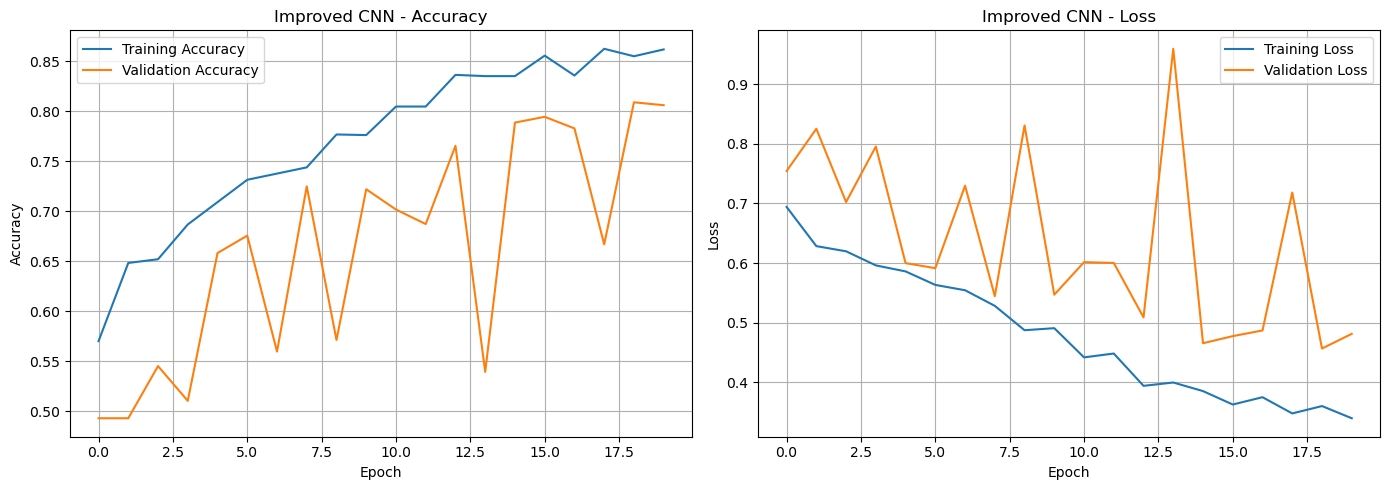

In [66]:
# Plot improved CNN learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    improved_history.history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    improved_history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("Improved CNN - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(
    improved_history.history["loss"],
    label="Training Loss"
)

axes[1].plot(
    improved_history.history["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("Improved CNN - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [68]:
# Compare model performance
model_comparison = pd.DataFrame({
    "Model": [
        "Original CNN",
        "Improved CNN"
    ],
    "Best Validation Accuracy": [
        history_df["val_accuracy"].max(),
        improved_history_df["val_accuracy"].max()
    ],
    "Best Validation Loss": [
        history_df["val_loss"].min(),
        improved_history_df["val_loss"].min()
    ]
})

display(
    model_comparison.round(4)
)

,Model,Best Validation Accuracy,Best Validation Loss
0,Original CNN,0.7333,0.5391
1,Improved CNN,0.8087,0.4565


# Final model evaluation

In [69]:
# Step 14: Final Model Evaluation

best_model = tf.keras.models.load_model(
    str(improved_checkpoint_path)
)

print("Best CNN model loaded successfully.")

Best CNN model loaded successfully.


In [71]:
# Evaluate on test dataset

test_results = best_model.evaluate(
    test_dataset,
    verbose=1,
    return_dict=True
)

print("\nFinal Test Results")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.8208 - loss: 0.4251 - precision: 0.8214 - recall: 0.8118

Final Test Results
accuracy: 0.8208
loss: 0.4251
precision: 0.8214
recall: 0.8118


In [72]:
# Generate test predictions
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Actual labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_dataset
])

# Predicted probabilities
y_prob = best_model.predict(test_dataset).ravel()

# Convert probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Actual Labels Shape:", y_true.shape)
print("Predicted Labels Shape:", y_pred.shape)
print("Predictions generated successfully.")

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step
Actual Labels Shape: (346,)
Predicted Labels Shape: (346,)
Predictions generated successfully.


In [74]:
# Calculate classification metrics
print("FINAL TEST CLASSIFICATION METRICS")
print("-" * 45)

print("Accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("Precision:",
      round(precision_score(y_true, y_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_true, y_pred, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_true, y_pred, zero_division=0), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_true, y_prob), 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Man", "Woman"],
        zero_division=0
    )
)

FINAL TEST CLASSIFICATION METRICS
---------------------------------------------
Accuracy: 0.8208
Precision: 0.8214
Recall: 0.8118
F1 Score: 0.8166
ROC-AUC: 0.8878

Classification Report:

              precision    recall  f1-score   support

         Man       0.82      0.83      0.82       176
       Woman       0.82      0.81      0.82       170

    accuracy                           0.82       346
   macro avg       0.82      0.82      0.82       346
weighted avg       0.82      0.82      0.82       346



# Confusion matrix and ROC curve

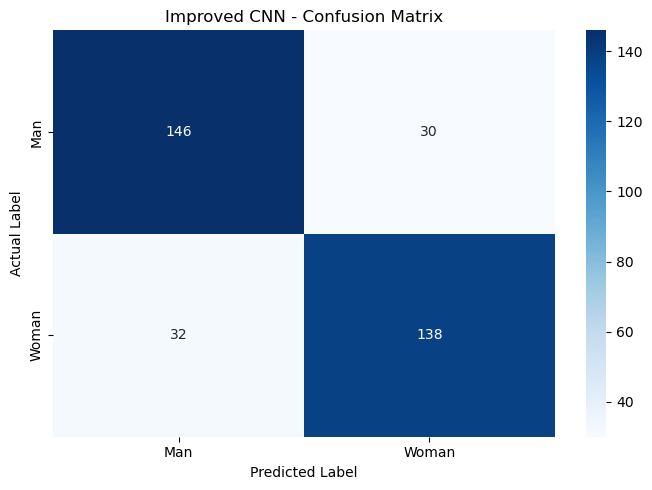

Confusion Matrix:
[[146  30]
 [ 32 138]]


In [75]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Man", "Woman"],
    yticklabels=["Man", "Woman"]
)

plt.title("Improved CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

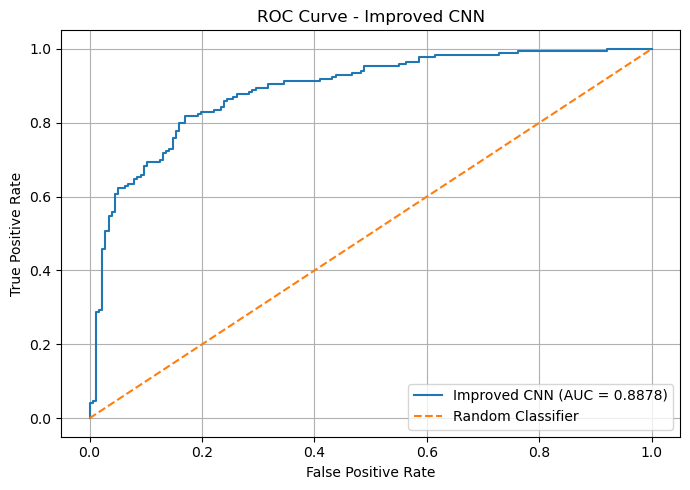

In [76]:
# ROC curve
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Improved CNN (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Improved CNN")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [78]:
# Save final evaluation metrics
final_metrics = {
    "Model": "Improved CNN",
    "Test Accuracy": accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred),
    "Recall": recall_score(y_true, y_pred),
    "F1 Score": f1_score(y_true, y_pred),
    "ROC-AUC": roc_auc_score(y_true, y_prob)
}

final_metrics_df = pd.DataFrame([final_metrics])

display(final_metrics_df.round(4))

final_metrics_df.to_csv(
    "gender_detection_final_metrics.csv",
    index=False
)

print("Final evaluation metrics saved successfully.")

,Model,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Improved CNN,0.8208,0.8214,0.8118,0.8166,0.8878


Final evaluation metrics saved successfully.


# Misclassified Image Analysis

In [81]:
# Create prediction results DataFrame

test_results_df = test_df.reset_index(drop=True).copy()

test_results_df["actual_label"] = y_true
test_results_df["predicted_label"] = y_pred
test_results_df["predicted_probability_woman"] = y_prob

label_names = {
    0: "Man",
    1: "Woman"
}

test_results_df["actual_name"] = (
    test_results_df["actual_label"].map(label_names)
)

test_results_df["predicted_name"] = (
    test_results_df["predicted_label"].map(label_names)
)

misclassified_df = test_results_df[
    test_results_df["actual_label"] != test_results_df["predicted_label"]
].copy()

print("Total test images:", len(test_results_df))
print("Correct predictions:", len(test_results_df) - len(misclassified_df))
print("Misclassified images:", len(misclassified_df))

display(
    misclassified_df[
        [
            "filename",
            "actual_name",
            "predicted_name",
            "predicted_probability_woman"
        ]
    ].head(10)
)

Total test images: 346
Correct predictions: 284
Misclassified images: 62


,filename,actual_name,predicted_name,predicted_probability_woman
4,face_1337.jpg,Man,Woman,0.988298
5,face_577.jpg,Woman,Man,0.158075
13,face_948.jpg,Woman,Man,0.373468
14,face_925.jpg,Woman,Man,0.141964
23,face_558.jpg,Woman,Man,0.464561
30,face_698.jpg,Man,Woman,0.754801
35,face_431.jpg,Man,Woman,0.663833
40,face_429.jpg,Woman,Man,0.379867
46,face_85.jpg,Woman,Man,0.088750
48,face_640.jpg,Woman,Man,0.420476


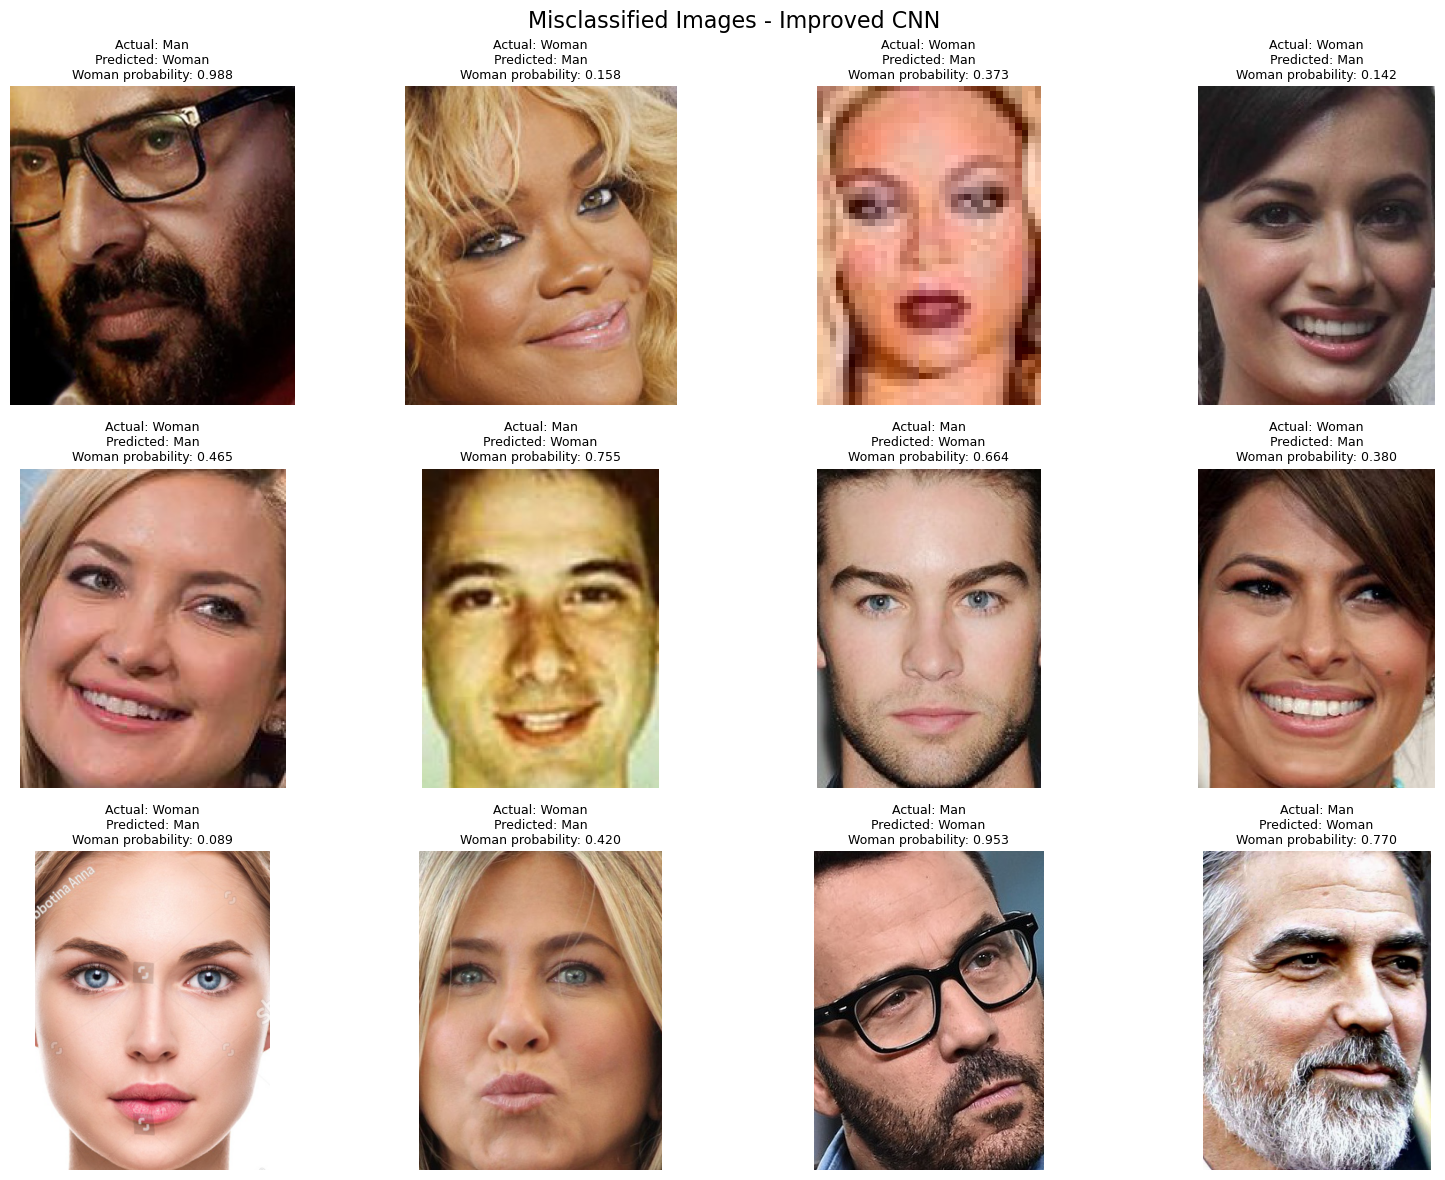

In [82]:
## Display misclassified images

import math
import matplotlib.pyplot as plt
from PIL import Image

num_images = min(12, len(misclassified_df))
cols = 4
rows = math.ceil(num_images / cols)

plt.figure(figsize=(16, rows * 4))

for i, (_, row) in enumerate(misclassified_df.head(num_images).iterrows()):
    image = Image.open(row["filepath"]).convert("RGB")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(image)

    plt.title(
        f"Actual: {row['actual_name']}\n"
        f"Predicted: {row['predicted_name']}\n"
        f"Woman probability: {row['predicted_probability_woman']:.3f}",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("Misclassified Images - Improved CNN", fontsize=16)
plt.tight_layout()
plt.show()

# Save Final Model Artifacts

In [87]:
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

final_model_path = model_dir / "gender_detection_final.keras"

best_model.save(final_model_path)

print("Final model saved successfully!")
print("Model path:", final_model_path.resolve())
print("File size (MB):", round(final_model_path.stat().st_size / (1024 * 1024), 2))

Final model saved successfully!
Model path: C:\Users\prana\Project For ML\PRAICP-1001-GenderDetc\models\gender_detection_final.keras
File size (MB): 0.4


In [88]:
import json

label_names = {
    "0": "Man",
    "1": "Woman"
}

label_mapping_path = model_dir / "label_mapping.json"

with open(label_mapping_path, "w") as file:
    json.dump(label_names, file, indent=4)

print("Label mapping saved:", label_mapping_path.resolve())

Label mapping saved: C:\Users\prana\Project For ML\PRAICP-1001-GenderDetc\models\label_mapping.json


In [89]:
metrics_path = model_dir / "gender_detection_final_metrics.csv"

final_metrics_df.to_csv(metrics_path, index=False)

print("Evaluation metrics saved:", metrics_path.resolve())

Evaluation metrics saved: C:\Users\prana\Project For ML\PRAICP-1001-GenderDetc\models\gender_detection_final_metrics.csv


In [91]:
loaded_model = tf.keras.models.load_model(
    "models/gender_detection_final.keras"
)

print("Saved model loaded successfully!")
print("Model input shape:", loaded_model.input_shape)
print("Model output shape:", loaded_model.output_shape)

Saved model loaded successfully!
Model input shape: (None, 160, 160, 3)
Model output shape: (None, 1)


In [93]:
# Test a prediction using the saved model

sample_path = test_df.iloc[0]["filepath"]

image = tf.io.read_file(sample_path)
image = tf.io.decode_jpeg(image, channels=3)
image = tf.cast(image, tf.float32)
image = tf.image.resize_with_pad(image, IMG_SIZE, IMG_SIZE)
image = image / 255.0
image = tf.expand_dims(image, axis=0)

probability = float(loaded_model.predict(image, verbose=0)[0][0])

predicted_label = "Woman" if probability >= 0.5 else "Man"

actual_label = label_names[str(int(test_df.iloc[0]["label"]))]

print("Image:", Path(sample_path).name)
print("Actual dataset label:", actual_label)
print("Predicted label:", predicted_label)
print("Woman probability:", round(probability, 4))
print("Man probability:", round(1 - probability, 4))

Image: face_253.jpg
Actual dataset label: Man
Predicted label: Man
Woman probability: 0.0647
Man probability: 0.9353


# Create a Reusable Prediction Function

In [94]:
# Define the prediction function

def predict_gender_label(image_path, model=loaded_model):
    """
    Predict the dataset label (Man/Woman) for an image.
    This predicts dataset categories, not gender identity.
    """

    image = tf.io.read_file(str(image_path))
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.cast(image, tf.float32)
    image = tf.image.resize_with_pad(image, IMG_SIZE, IMG_SIZE)
    image = image / 255.0
    image = tf.expand_dims(image, axis=0)

    probability = float(model.predict(image, verbose=0)[0][0])

    predicted_label = "Woman" if probability >= 0.5 else "Man"

    return {
        "predicted_label": predicted_label,
        "woman_probability": round(probability, 4),
        "man_probability": round(1 - probability, 4)
    }

In [95]:
# Test the reusable function
sample_image_path = test_df.iloc[10]["filepath"]

prediction_result = predict_gender_label(sample_image_path)

print("Image:", Path(sample_image_path).name)
print("Prediction:", prediction_result["predicted_label"])
print("Woman probability:", prediction_result["woman_probability"])
print("Man probability:", prediction_result["man_probability"])

Image: face_600.jpg
Prediction: Woman
Woman probability: 0.944
Man probability: 0.056
